#**INTRO**
**Dokumen** : A Multistep Prediction of Hydropower Station Inflow Based on Bagging-LSTM Model</br>
**Dataset** : [The Inflow Prediction](https://github.com/HYNU-WLL/The-Inflow-Prediction/tree/main/datasets)</br>
**Konteks** :</br>
Membangun model prediksi aliran masuk (*inflow*) ke pembangkit listrik tenaga air (PLTA). Dataset inflow (tersedia dari tahun 2015 s.d. 2017) terdiri dari dua kolom utama:
1. **Timestample** → Waktu pencatatan inflow dengan interval 3 jam.
2. **Qi** (m³/s atau mm) → Volume air yang masuk ke waduk PLTA.</br>





#**Import Library**

In [ ]:
!pip install nolds

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.1/225.1 kB 3.9 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
#from nolds import lyap_r
import pickle

##**Memuat Data**

In [ ]:
# Memuat dataset inflow
dataset_src = 'https://raw.githubusercontent.com/HYNU-WLL/The-Inflow-Prediction/main/datasets/Inflow_Data.csv'

df_inflow = pd.read_csv(dataset_src, parse_dates=['TimeStample'], index_col='TimeStample')
df_inflow

,Qi
TimeStample,
2015-01-01 02:00:00,0.018577
2015-01-01 05:00:00,0.018577
2015-01-01 08:00:00,0.018577
2015-01-01 11:00:00,0.017673
2015-01-01 14:00:00,0.024000
...,...
2017-12-31 11:00:00,0.022744
2017-12-31 14:00:00,0.031933
2017-12-31 17:00:00,0.025255


#**EDA**

**Struktur Data**

In [ ]:
# Meninjau jumlah baris dan kolom dataset
print(f"Ukuran dataset: {df_inflow.shape}\n\n")

# Meninjau jenis data tiap kolom (numerikal/kategorikal)
print("Info 'Inflow_Data.csv' data:")
df_inflow.info()

Ukuran dataset: (8768, 1)


Info 'Inflow_Data.csv' data:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8768 entries, 2015-01-01 02:00:00 to 2017-12-31 23:00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Qi      8768 non-null   float64
dtypes: float64(1)
memory usage: 137.0 KB


**Visualisasi Time-Series Data**

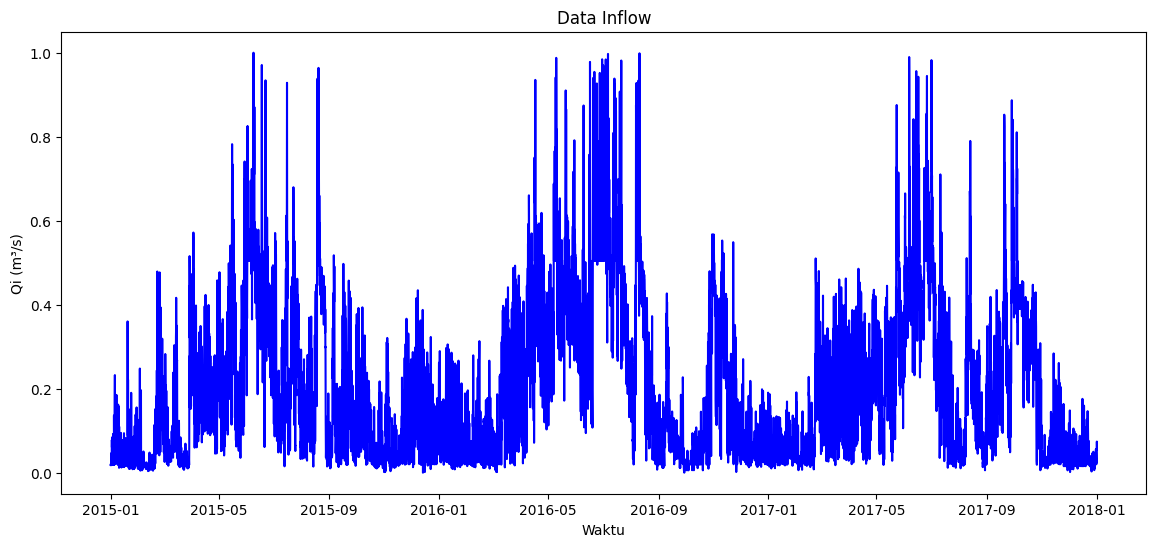

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(df_inflow['Qi'], label='Qi', color='b')
plt.xlabel('Waktu')
plt.ylabel('Qi (m³/s)')
plt.title('Data Inflow')
plt.show()

**Uji Stasioneritas Data**

In [ ]:
def adf_test(timeseries):
    print ('Results of Dickey-Fuller Test:')
    uji_adf = adfuller(timeseries, autolag = 'AIC')
    hasil_adf = pd.Series(uji_adf[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])

    for key,value in uji_adf[4].items():
        hasil_adf['Critical Value (%s)'%key] = value
    print (hasil_adf)

    # cek stationeritas data
    critical_value = hasil_adf['Critical Value (5%)']
    test_statistic = hasil_adf['Test Statistic']
    alpha = 1e-3
    pvalue = uji_adf[1]

    if pvalue < alpha and test_statistic < critical_value:  # null hypothesis: x is non stationary
        print("X is stationary")
        return True
    else:
        print("X is not stationary")
        return False

In [ ]:
# Penanganan jika data tidak stasioner
stationary_data = pd.Series(df_inflow['Qi'])
d = 0

while adf_test(stationary_data) is False:
    stationary_data = stationary_data.diff().dropna()
    d = d + 1
    print(f'Differencing order: {d}')

Results of Dickey-Fuller Test:
Test Statistic                -5.972328e+00
p-value                        1.923124e-07
#Lags Used                     3.500000e+01
Number of Observations Used    8.732000e+03
Critical Value (1%)           -3.431099e+00
Critical Value (5%)           -2.861871e+00
Critical Value (10%)          -2.566946e+00
dtype: float64
X is stationary


**Analisa Atuo-korelasi Data**

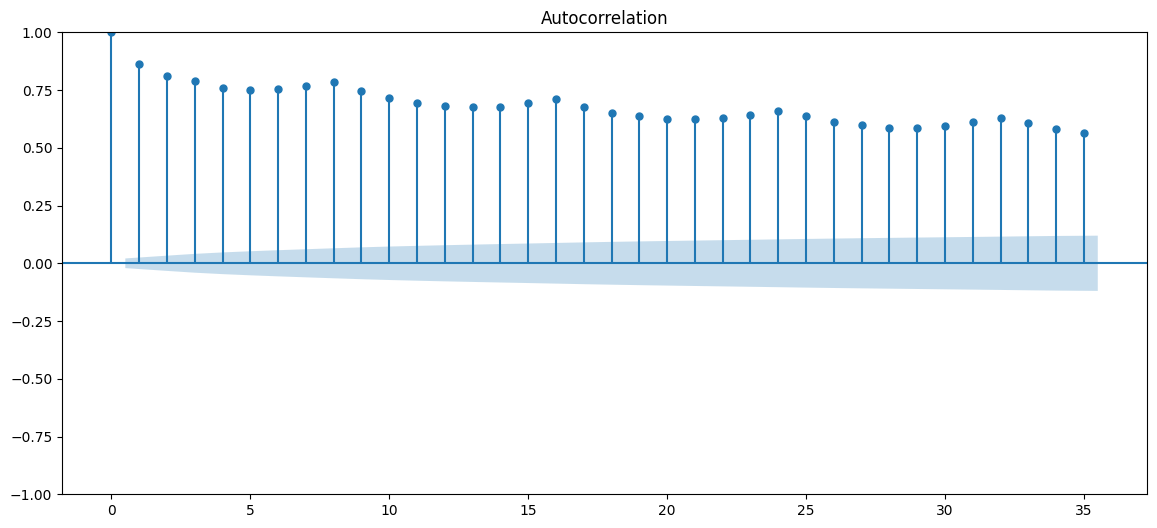

In [ ]:
# Autocorrelation Function (ACF)
fig, ax = plt.subplots(figsize=(14, 6))
plot_acf(df_inflow['Qi'], lags=35, ax=ax)
plt.show()

Data mengalami pola penurunan (tetapi berosilasi --> kemungkinan data menunjukkan tren musiman) menunjukkan dataset 'Inflow_Data.csv' menggambarkan adanya korelasi signifikan secara statistik = ada hubungan dengan nilai sebelumnya (bukan sekadar fluktuasi)

#**Pre-processing Data**

**Splitting Data**

In [ ]:
# Splitting data training (70%), validation (15%), and testing (15%)
train_size = int(len(df_inflow['Qi']) * 0.70)
val_size = int(len(df_inflow['Qi']) * 0.15)
test_size = len(df_inflow['Qi']) - train_size - val_size

train_data = df_inflow['Qi'].iloc[:train_size]
val_data = df_inflow['Qi'].iloc[train_size:train_size + val_size]
test_data = df_inflow['Qi'].iloc[train_size + val_size:]

print("Jumlah data:")
print(f'Training: {len(train_data)}, Validation: {len(val_data)}, Testing: {len(test_data)}')

Jumlah data:
Training: 6137, Validation: 1315, Testing: 1316


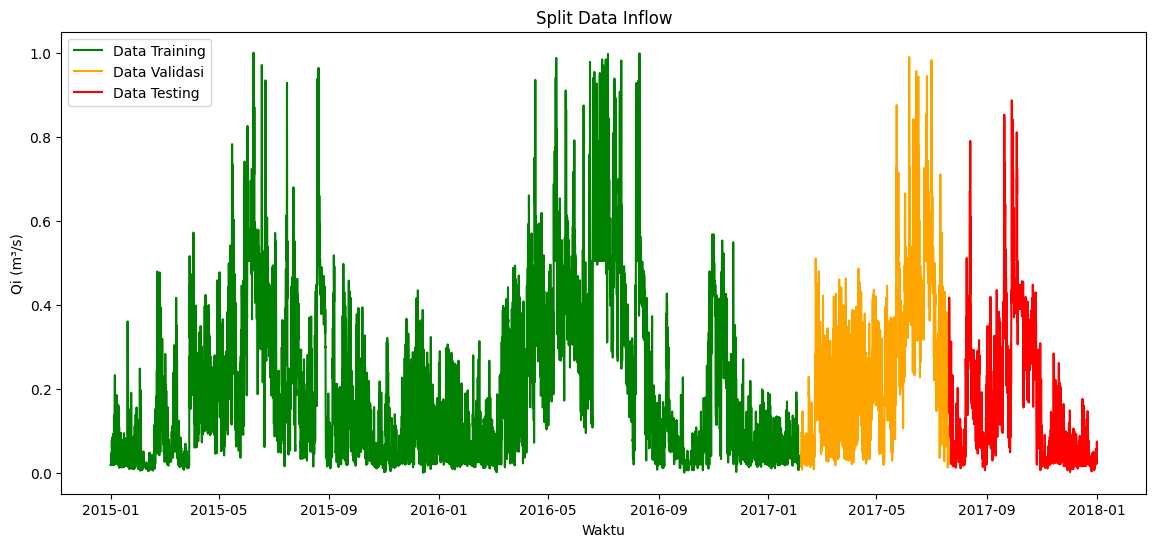

In [ ]:
# Visualisasi splitting data
plt.figure(figsize=(14, 6))
plt.plot(train_data.index, train_data.values, label='Data Training', color='green')
plt.plot(val_data.index, val_data.values, label='Data Validasi', color='orange')
plt.plot(test_data.index, test_data.values, label='Data Testing', color='red')
plt.title('Split Data Inflow')
plt.xlabel('Waktu')
plt.ylabel('Qi (m³/s)')
plt.legend()
plt.show()

**Fixed Data**

In [ ]:
def create_sequences(data, window_size, output_size):
    X, T = [], []
    for i in range(len(data) - window_size - output_size + 1):
        X.append(data[i:i+window_size])                          # Ambil 35 titik sebelumnya sebagai input
        T.append(data[i+window_size:i+window_size+output_size])  # Ambil 3 titik berikutnya sebagai output
    return np.array(X), np.array(T)

# Terapkan ke masing-masing split dataset
window_size = 35
output_size = 5

train_X, train_T = create_sequences(train_data.values, window_size, output_size)
val_X, val_T = create_sequences(val_data.values, window_size, output_size)
test_X, test_T = create_sequences(test_data.values, window_size, output_size)

# Ukuran pemetaan input-output dataset
print(f"X_train: {train_X.shape}, T_train: {train_T.shape}")
print(f"X_val: {val_X.shape}, T_val: {val_T.shape}")
print(f"X_test: {test_X.shape}, T_test: {test_T.shape}")

X_train: (6098, 35), T_train: (6098, 5)
X_val: (1276, 35), T_val: (1276, 5)
X_test: (1277, 35), T_test: (1277, 5)


In [ ]:
# Data frame training
column_names = [f"X{i+1}" for i in range(window_size)]  # Nama kolom input (35 lag sebelumnya)
output_names = [f"T{i+1}" for i in range(output_size)]  # Nama kolom output (5 prediksi ke depan)

df_train = pd.DataFrame(np.hstack((train_X, train_T)), columns=column_names + output_names)

pd.set_option('display.float_format', '{:.4f}'.format)
df_train

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X31,X32,X33,X34,X35,T1,T2,T3,T4,T5
0,0.0186,0.0186,0.0186,0.0177,0.0240,0.0186,0.0220,0.0469,0.0187,0.0187,...,0.1364,0.0625,0.0187,0.0559,0.0791,0.1023,0.1094,0.1767,0.2324,0.0558
1,0.0186,0.0186,0.0177,0.0240,0.0186,0.0220,0.0469,0.0187,0.0187,0.0252,...,0.0625,0.0187,0.0559,0.0791,0.1023,0.1094,0.1767,0.2324,0.0558,0.1766
2,0.0186,0.0177,0.0240,0.0186,0.0220,0.0469,0.0187,0.0187,0.0252,0.0779,...,0.0187,0.0559,0.0791,0.1023,0.1094,0.1767,0.2324,0.0558,0.1766,0.0372
3,0.0177,0.0240,0.0186,0.0220,0.0469,0.0187,0.0187,0.0252,0.0779,0.0606,...,0.0559,0.0791,0.1023,0.1094,0.1767,0.2324,0.0558,0.1766,0.0372,0.0605
4,0.0240,0.0186,0.0220,0.0469,0.0187,0.0187,0.0252,0.0779,0.0606,0.0790,...,0.0791,0.1023,0.1094,0.1767,0.2324,0.0558,0.1766,0.0372,0.0605,0.0379
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6093,0.0550,0.1436,0.1914,0.0902,0.0459,0.0257,0.1672,0.1081,0.0608,0.0485,...,0.0139,0.0337,0.0354,0.0397,0.0383,0.0404,0.0332,0.0192,0.0192,0.0192
6094,0.1436,0.1914,0.0902,0.0459,0.0257,0.1672,0.1081,0.0608,0.0485,0.0211,...,0.0337,0.0354,0.0397,0.0383,0.0404,0.0332,0.0192,0.0192,0.0192,0.0378
6095,0.1914,0.0902,0.0459,0.0257,0.1672,0.1081,0.0608,0.0485,0.0211,0.0454,...,0.0354,0.0397,0.0383,0.0404,0.0332,0.0192,0.0192,0.0192,0.0378,0.0289
6096,0.0902,0.0459,0.0257,0.1672,0.1081,0.0608,0.0485,0.0211,0.0454,0.0571,...,0.0397,0.0383,0.0404,0.0332,0.0192,0.0192,0.0192,0.0378,0.0289,0.0305


#**Implementasi BPNN**

**Inisialisiasi Model BPNN**

In [ ]:
# Inisialisasi struktur BPNN
NI = window_size       # input neuron = 35
NH = 5                 # hidden neuron
hiddenLayer = 1        # hidden layer
NO = output_size       # output neuron

# Inisialisasi bobot dan bias
np.random.seed(42)
v = np.random.rand(NI, NH)
vb = np.random.rand(NH)
w = np.random.rand(NH, NO)
wb = np.random.rand(NO)

# Inisialisasi parameter lain
lr = 0.001      # learning rate
epoch = 10000
patience = 50
best_mse = float("inf")
best_weights = None

In [ ]:
# Ukuran bobot dan bias model BPNN
print(f"Bobot v: {v.shape}, Bias vb: {vb.shape}")
print(f"Bobot w: {w.shape}, Bias wb: {wb.shape}")

Bobot v: (35, 5), Bias vb: (5,)
Bobot w: (5, 5), Bias wb: (5,)


**Fungsi Aktivasi**

In [ ]:
# fungsi sigmoid
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def d_sigmoid(x):
    return sigmoid(x) * (1 - sigmoid(x))

# fungsi RELu
def relu(x):
    return np.maximum(0, x)

def d_relu(x):
    return np.where(x > 0, 1, 0)

# fungsi softmax
#def softmax(x):
    exps = np.exp(x - np.max(x))  # Stabilize softmax by subtracting max
    return exps / np.sum(exps)

**BPNN**

In [ ]:
# BPNN
train_error_log = []
val_error_log = []

for e in range(epoch):
    total_error = 0

    for i in range(len(train_X)):
        x = train_X[i]
        t = train_T[i]

        # Forward Propagation
        z_in = np.dot(x, v) + vb           # sinyal input unit hidden + bobot
        z = sigmoid(z_in)                  # sinyal output unit hidden
        y_in = np.dot(z, w) + wb           # sinyal input unit output + bobot
        y = y_in                           # sinyal output unit output

        # Compute Error
        sample_error = 0.5 * np.sum((t - y) ** 2)
        total_error += sample_error

        # Backpropagation
        # Output Layer Error
        del_y = (t - y)                     # infromasi error

        # Weight update for output layer
        delta_w = lr * np.outer(z, del_y)   # koreksi bobot unit output
        delta_wb = lr * del_y               # koreksi bias unit output

        # Hidden Layer Error
        del_in = np.dot(del_y, w.T)         # koreksi error unit hidden
        delj = del_in * z * (1 - z)         # aktivasi koreksi error unit hidden

        # Weight update for hidden layer
        delta_v = lr * np.outer(x, delj)    # koreksi bobot unit hidden
        delta_vb = lr * delj                # koreksi bias unit hidden

        # Update Weights
        w += delta_w
        wb += delta_wb.flatten()
        v += delta_v
        vb += delta_vb.flatten()

    # Calculate Validation Loss
    predictions = []
    for i in range(len(val_X)):
        x = val_X[i]
        z_in = np.dot(x, v) + vb
        z = sigmoid(z_in)
        y_in = np.dot(z, w) + wb
        y = y_in
        predictions.append(y)

    predictions = np.array(predictions)
    val_mse = np.mean((val_T - predictions) ** 2)

    # Store errors for plotting
    train_error_log.append(total_error / len(train_X))  # Append train error
    val_error_log.append(val_mse)  # Append validation error

    # Check Early Stopping
    if val_mse < best_mse:
        best_mse = val_mse
        best_weights = (v.copy(), vb.copy(), w.copy(), wb.copy())
        no_improve_epochs = 0
    else:
        no_improve_epochs += 1

    # Print progress
    if (e + 1) % 100 == 0:
        print(f"Epoch {e+1}, Train MSE: {total_error / len(train_X)}, Val MSE: {val_mse}")

    # Stop if no improvement for `patience` epochs
    if no_improve_epochs >= patience:
        print(f"Early stopping at epoch {e+1} || Best Val MSE: {best_mse}")
        break

# Restore Best Weights
if best_weights:
    v, vb, w, wb = best_weights

Epoch 100, Train MSE: 0.026649455669107945, Val MSE: 0.016314442440685136
Epoch 200, Train MSE: 0.023920174316220573, Val MSE: 0.014467741058002609
Epoch 300, Train MSE: 0.023269620753392836, Val MSE: 0.014023797942123847
Epoch 400, Train MSE: 0.022942207138351132, Val MSE: 0.013768779036452882
Epoch 500, Train MSE: 0.022728511458736212, Val MSE: 0.01357937732432408
Epoch 600, Train MSE: 0.022573456264951497, Val MSE: 0.013429277224630724
Epoch 700, Train MSE: 0.022452260859128884, Val MSE: 0.013308948328867403
Epoch 800, Train MSE: 0.02235105259803756, Val MSE: 0.013209988618772938
Epoch 900, Train MSE: 0.022264222254267482, Val MSE: 0.013126575988671393
Epoch 1000, Train MSE: 0.022190347678030697, Val MSE: 0.013056012919309867
Epoch 1100, Train MSE: 0.02212831145274959, Val MSE: 0.012996695683044469
Epoch 1200, Train MSE: 0.02207610085326998, Val MSE: 0.01294682052015467
Epoch 1300, Train MSE: 0.02203156759193263, Val MSE: 0.012904500013879957
Epoch 1400, Train MSE: 0.021993115470178

**Evaluasi**

**Grafik Training-Validation Error**

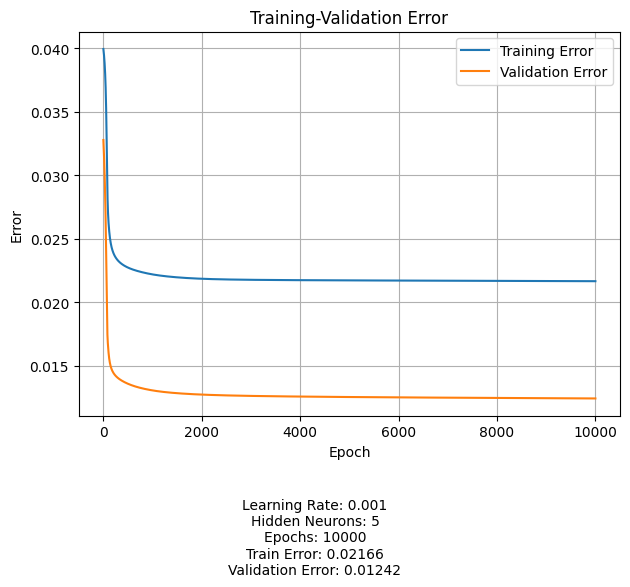

In [ ]:
last_epoch = len(train_error_log)
avg_train_error = np.mean(train_error_log[-10:])
best_val_error = np.min(val_error_log)
annotation_text = f"Learning Rate: {lr}\nHidden Neurons: {NH}\nEpochs: {last_epoch}\nTrain Error: {avg_train_error:.5f}\nValidation Error: {best_val_error:.5f}"

fig, ax = plt.subplots()
ax.plot(train_error_log, label='Training Error')
ax.plot(val_error_log, label='Validation Error')
ax.set_xlabel('Epoch')
ax.set_ylabel('Error')
ax.set_title('Training-Validation Error')
ax.grid(True)
ax.legend()
fig.text(0.5, -0.05, annotation_text, ha='center', va='top')

plt.tight_layout()
plt.show()

**Prediksi**

In [ ]:
test_predictions = []
for i in range(len(test_X)):
    x = test_X[i]
    z_in = np.dot(x, v) + vb
    z = sigmoid(z_in)
    y_in = np.dot(z, w) + wb
    y = y_in
    test_predictions.append(y)

test_predictions = np.array(test_predictions)
test_mse = np.mean((test_T - test_predictions) ** 2)
print("Final Test MSE:", test_mse)

Final Test MSE: 0.0056681204125147485


#**Menyimpan Model**

In [ ]:
# Menyimpan model BPNN ke file
model_filename = 'bpnn_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump((v, vb, w, wb), file)

print(f"Model BPNN berhasil disimpan ke {model_filename}")

Model BPNN berhasil disimpan ke bpnn_model.pkl
